# JS06 (Regresi) - Praktikum 2: Support Vector Regression (SVR)
**Mata Kuliah:** Pembelajaran Mesin  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Deskripsi
Penerapan SVR non-linier kernel RBF pada dataset `Posisi_gaji.csv` untuk memprediksi gaji berdasarkan tingkat posisi jabatan.


            Position  Level   Salary
0   Business Analyst      1    45000
1  Junior Consultant      2    50000
2  Senior Consultant      3    60000
3            Manager      4    80000
4    Country Manager      5   110000
5     Region Manager      6   150000
6            Partner      7   200000
7     Senior Partner      8   300000
8            C-level      9   500000
9                CEO     10  1000000
Prediksi Gaji untuk Tingkat Posisi 6.5: $170,370.02
MAE       : 0.22299274095734414
MSE       : 0.24839989293792014
RMSE      : 0.4983973243687411
R-squared : 0.7516001070620798


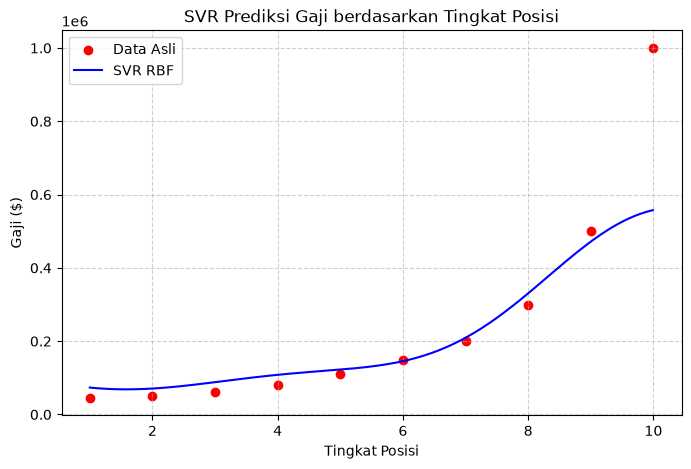

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Import Dataset
dataset = pd.read_csv('Posisi_gaji.csv')
display(dataset)

X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values

# 2. Feature Scaling
sc_X = StandardScaler()
sc_y = StandardScaler()
X_scaled = sc_X.fit_transform(X)
y_scaled = sc_y.fit_transform(y.reshape(-1, 1)).ravel()

# 3. Fitting SVR RBF
regressor = SVR(kernel='rbf', C=1.0, epsilon=0.1)
regressor.fit(X_scaled, y_scaled)

# 4. Visualisasi Kurva Halus
X_grid = np.arange(float(X_scaled.min()), float(X_scaled.max()), 0.01).reshape(-1, 1)
plt.figure(figsize=(8, 5))
plt.scatter(sc_X.inverse_transform(X_scaled), sc_y.inverse_transform(y_scaled.reshape(-1,1)), color='red', label='Data Asli')
plt.plot(sc_X.inverse_transform(X_grid), sc_y.inverse_transform(regressor.predict(X_grid).reshape(-1,1)), color='blue', label='SVR RBF')
plt.title('SVR Prediksi Gaji berdasarkan Tingkat Posisi')
plt.xlabel('Tingkat Posisi')
plt.ylabel('Gaji ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 5. Prediksi Tingkat Posisi 6.5
posisi_pred = np.array([[6.5]])
gaji_pred_scaled = regressor.predict(sc_X.transform(posisi_pred))
gaji_pred = sc_y.inverse_transform(gaji_pred_scaled.reshape(-1, 1))
print(f"Prediksi Gaji untuk Tingkat Posisi 6.5: ${gaji_pred[0][0]:,.2f}")

# 6. Evaluasi Metrik
y_pred_scaled = regressor.predict(X_scaled)
print("MAE       :", mean_absolute_error(y_scaled, y_pred_scaled))
print("MSE       :", mean_squared_error(y_scaled, y_pred_scaled))
print("RMSE      :", np.sqrt(mean_squared_error(y_scaled, y_pred_scaled)))
print("R-squared :", r2_score(y_scaled, y_pred_scaled))
